## Google Data Analytics Capstone Project: Cyclistic bike-share analysis case study

Author: Lucia Merlassino

### About the company

Cyclistic is a fictional bike-share company in Chicago with 5,824 bicycles and 692 stations. It offers two types of plans: single-ride/full-day passes and annual memberships.

### Business Goal
The primary focus of this analysis is to distinguish between casual riders (who purchase single-ride or full-day passes) and annual members in order to develop strategies for converting casual riders into annual members.

### About the Dataset
The data has been provided by Motivate International Inc. under a royalty-free licence. The analysis was based on the data from the full year 2025.

**INSTALL AND LOAD LIBRARIES**


In [1]:
#Load relevant libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**LOAD CSV FILES**


In [2]:
# Upload Divvy datasets (csv files)
data_2025_01 = pd.read_csv("bikes_2025_01.csv")
data_2025_02 = pd.read_csv("bikes_2025_02.csv")
data_2025_03 = pd.read_csv("bikes_2025_03.csv")
data_2025_04 = pd.read_csv("bikes_2025_04.csv")
data_2025_05 = pd.read_csv("bikes_2025_05.csv")
data_2025_06 = pd.read_csv("bikes_2025_06.csv")
data_2025_07 = pd.read_csv("bikes_2025_07.csv")
data_2025_08 = pd.read_csv("bikes_2025_08.csv")
data_2025_09 = pd.read_csv("bikes_2025_09.csv")
data_2025_10 = pd.read_csv("bikes_2025_10.csv")
data_2025_11 = pd.read_csv("bikes_2025_11.csv")
data_2025_12 = pd.read_csv("bikes_2025_12.csv")


In [3]:
#Check equality between column names for each of the files

months = [f"2025_{m:02d}" for m in range(1, 13)]
dfs = {m: pd.read_csv(f"bikes_{m}.csv") for m in months}

base_cols = list(dfs["2025_01"].columns)
print("Base columns (2025_01):", base_cols)

for m, df in dfs.items():
    current_cols = list(df.columns)
    same_exact = current_cols == base_cols
    same_set = set(current_cols) == set(base_cols)
    print(f"{m} -> exact_match: {same_exact} | same_names_any_order: {same_set}")
    if not same_exact:
        print("   Diff vs base:", set(base_cols) ^ set(current_cols))


Base columns (2025_01): ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']
2025_01 -> exact_match: True | same_names_any_order: True
2025_02 -> exact_match: True | same_names_any_order: True
2025_03 -> exact_match: True | same_names_any_order: True
2025_04 -> exact_match: True | same_names_any_order: True
2025_05 -> exact_match: True | same_names_any_order: True
2025_06 -> exact_match: True | same_names_any_order: True
2025_07 -> exact_match: True | same_names_any_order: True
2025_08 -> exact_match: True | same_names_any_order: True
2025_09 -> exact_match: True | same_names_any_order: True
2025_10 -> exact_match: True | same_names_any_order: True
2025_11 -> exact_match: True | same_names_any_order: True
2025_12 -> exact_match: True | same_names_any_order: True


In [4]:
# Inspect the data frames and look for incongruities
print("\n2025_01 Data Info:")
data_2025_01.info()
print("\n2025_02 Data Info:")
data_2025_02.info()
print("\n2025_03 Data Info:")
data_2025_03.info()
print("\n2025_04 Data Info:")
data_2025_04.info()
print("\n2025_05 Data Info:")
data_2025_05.info()
print("\n2025_06 Data Info:")
data_2025_06.info()
print("\n2025_07 Data Info:")
data_2025_07.info()
print("\n2025_08 Data Info:")
data_2025_08.info()
print("\n2025_09 Data Info:")
data_2025_09.info()
print("\n2025_10 Data Info:")
data_2025_10.info()
print("\n2025_11 Data Info:")
data_2025_11.info()
print("\n2025_12 Data Info:")
data_2025_12.info()



2025_01 Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138689 entries, 0 to 138688
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             138689 non-null  object 
 1   rideable_type       138689 non-null  object 
 2   started_at          138689 non-null  object 
 3   ended_at            138689 non-null  object 
 4   start_station_name  115837 non-null  object 
 5   start_station_id    115837 non-null  object 
 6   end_station_name    114616 non-null  object 
 7   end_station_id      114616 non-null  object 
 8   start_lat           138689 non-null  float64
 9   start_lng           138689 non-null  float64
 10  end_lat             138628 non-null  float64
 11  end_lng             138628 non-null  float64
 12  member_casual       138689 non-null  object 
dtypes: float64(4), object(9)
memory usage: 13.8+ MB

2025_02 Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeInd

* Key fields for time and user type analysis (ride_id, rideable_type, started_at, ended_at, start_lat, start_lng, and member_casual) have no missing values in any of the 12 months.

* Some data is missing in stations columns (start_station_name, start_station_id, end_station_name, end_station_id) and geolocation columns (end_lat / end_lng). Given that this analysis will concentrate on monthly patterns, days of the week, time length, and user/bike classification, those fields will be omitted.

In [5]:
# Convert ride_id and rideable_type to string so that they can stack correctly
data_2025_01['ride_id'] = data_2025_01['ride_id'].astype(str)
data_2025_01['rideable_type'] = data_2025_01['rideable_type'].astype(str)
data_2025_02['ride_id'] = data_2025_02['ride_id'].astype(str)
data_2025_02['rideable_type'] = data_2025_02['rideable_type'].astype(str)
data_2025_03['ride_id'] = data_2025_03['ride_id'].astype(str)
data_2025_03['rideable_type'] = data_2025_03['rideable_type'].astype(str)
data_2025_04['ride_id'] = data_2025_04['ride_id'].astype(str)
data_2025_04['rideable_type'] = data_2025_04['rideable_type'].astype(str)
data_2025_05['ride_id'] = data_2025_05['ride_id'].astype(str)
data_2025_05['rideable_type'] = data_2025_05['rideable_type'].astype(str)
data_2025_06['ride_id'] = data_2025_06['ride_id'].astype(str)
data_2025_06['rideable_type'] = data_2025_06['rideable_type'].astype(str)
data_2025_07['ride_id'] = data_2025_07['ride_id'].astype(str)
data_2025_07['rideable_type'] = data_2025_07['rideable_type'].astype(str)
data_2025_08['ride_id'] = data_2025_08['ride_id'].astype(str)
data_2025_08['rideable_type'] = data_2025_08['rideable_type'].astype(str)
data_2025_09['ride_id'] = data_2025_09['ride_id'].astype(str)
data_2025_09['rideable_type'] = data_2025_09['rideable_type'].astype(str)
data_2025_10['ride_id'] = data_2025_10['ride_id'].astype(str)
data_2025_10['rideable_type'] = data_2025_10['rideable_type'].astype(str)
data_2025_11['ride_id'] = data_2025_11['ride_id'].astype(str)
data_2025_11['rideable_type'] = data_2025_11['rideable_type'].astype(str)
data_2025_12['ride_id'] = data_2025_12['ride_id'].astype(str)
data_2025_12['rideable_type'] = data_2025_12['rideable_type'].astype(str)


In [6]:
# Stack all 12 monthly data frames into one data frame
all_trips = pd.concat(
    [
        data_2025_01,
        data_2025_02,
        data_2025_03,
        data_2025_04,
        data_2025_05,
        data_2025_06,
        data_2025_07,
        data_2025_08,
        data_2025_09,
        data_2025_10,
        data_2025_11,
        data_2025_12,
    ],
    ignore_index=True,
)


In [7]:
#Verify that the overall entries align with the aggregate of the 12 monthly tables.
len(all_trips)
#Ensure that the names and types of the columns remain unchanged
all_trips.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5552994 entries, 0 to 5552993
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 550.8+ MB


In [8]:
#Eliminate the latitude and longitude, station name, and station identifier columns as they are not needed for the temporal and customer type analysis
# The 'errors="ignore"' argument prevents an error if a column is not found
cols_to_drop = [
    "start_station_name",
    "start_station_id",
    "end_station_name",
    "end_station_id",
    "start_lat",
    "start_lng",
    "end_lat",
    "end_lng",
]

all_trips = all_trips.drop(columns=cols_to_drop)


**CLEAN UP AND ADD DATA TO PREPARE FOR ANALYSIS**

In [9]:
# Inspect the new table that has been created
print("\nList of column names:\n", all_trips.columns)
print("\nHow many rows are in data frame?", len(all_trips))
print("\nDimensions of the data frame:", all_trips.shape)
print("\nSee the first 6 rows of data frame:\n", all_trips.head())
print("\nSee list of columns and data types:\n")
all_trips.info()
# Statistical summary of data (mainly for numerics)
print("\nStatistical summary of data:\n", all_trips.describe())



List of column names:
 Index(['ride_id', 'rideable_type', 'started_at', 'ended_at', 'member_casual'], dtype='object')

How many rows are in data frame? 5552994

Dimensions of the data frame: (5552994, 5)

See the first 6 rows of data frame:
             ride_id  rideable_type               started_at  \
0  7569BC890583FCD7   classic_bike  2025-01-21 17:23:54.538   
1  013609308856B7FC  electric_bike  2025-01-11 15:44:06.795   
2  EACACD3CE0607C0D   classic_bike  2025-01-02 15:16:27.730   
3  EAA2485BA64710D3   classic_bike  2025-01-23 08:49:05.814   
4  7F8BE2471C7F746B  electric_bike  2025-01-16 08:38:32.338   

                  ended_at member_casual  
0  2025-01-21 17:37:52.015        member  
1  2025-01-11 15:49:11.139        member  
2  2025-01-02 15:28:03.230        member  
3  2025-01-23 08:52:40.047        member  
4  2025-01-16 08:41:06.767        member  

See list of columns and data types:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5552994 entries, 0 to 5552993
Da

In [10]:
#Include columns that provide additional opportunities to aggregate the data
#Add a calculated field for length of ride

# Convert 'started_at' and 'ended_at' to datetime objects
all_trips['started_at'] = pd.to_datetime(all_trips['started_at'])
all_trips['ended_at'] = pd.to_datetime(all_trips['ended_at'])

# Add a "ride_length" calculation to all_trips (in seconds)
all_trips['ride_length'] = (all_trips['ended_at'] - all_trips['started_at']).dt.total_seconds()

# Add columns that list the date, month, day, and year of each ride
all_trips['date'] = all_trips['started_at'].dt.date
all_trips['month'] = all_trips['started_at'].dt.month
all_trips['day'] = all_trips['started_at'].dt.day
all_trips['year'] = all_trips['started_at'].dt.year
all_trips['day_of_week'] = all_trips['started_at'].dt.day_name()


In [11]:
#Verify if any trips have a negative duration
print("Min ride_length:", all_trips["ride_length"].min())
print("Negative rides:", (all_trips["ride_length"] < 0).sum())
print("Zero-duration rides:", (all_trips["ride_length"] <= 0).sum())


Min ride_length: -3287.688
Negative rides: 29
Zero-duration rides: 29


In [12]:
# Inspect the structure of the columns
print("\nData types after adding date columns and ride_length:\n")
all_trips.info()



Data types after adding date columns and ride_length:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5552994 entries, 0 to 5552993
Data columns (total 11 columns):
 #   Column         Dtype         
---  ------         -----         
 0   ride_id        object        
 1   rideable_type  object        
 2   started_at     datetime64[ns]
 3   ended_at       datetime64[ns]
 4   member_casual  object        
 5   ride_length    float64       
 6   date           object        
 7   month          int32         
 8   day            int32         
 9   year           int32         
 10  day_of_week    object        
dtypes: datetime64[ns](2), float64(1), int32(3), object(5)
memory usage: 402.5+ MB


In [13]:
#Remove "bad" data
#The data frame includes entries where bikes were taken out of docks for quality checks or ride_length was negative
#Create a new version of the data frame (v2) since data is being removed

all_trips_v2 = all_trips[all_trips["ride_length"] >= 0].copy()


In [14]:
#verify the count of records discarded due to negative duration
all_trips_v2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5552965 entries, 0 to 5552993
Data columns (total 11 columns):
 #   Column         Dtype         
---  ------         -----         
 0   ride_id        object        
 1   rideable_type  object        
 2   started_at     datetime64[ns]
 3   ended_at       datetime64[ns]
 4   member_casual  object        
 5   ride_length    float64       
 6   date           object        
 7   month          int32         
 8   day            int32         
 9   year           int32         
 10  day_of_week    object        
dtypes: datetime64[ns](2), float64(1), int32(3), object(5)
memory usage: 444.8+ MB


29 rows were removed after applying the cleanup filter.

**CONDUCT DESCRIPTIVE ANALYSIS**


In [15]:
# Descriptive analysis on ride_length (all figures in seconds)
print("\nDescriptive statistics for ride_length:\n", all_trips_v2['ride_length'].describe())

# Compare members and casual users
print("\nRide length statistics grouped by member_casual:\n", all_trips_v2.groupby(['member_casual'], as_index=False, observed=False)['ride_length'].agg(['mean', 'median', 'max', 'min']))

# Order the days of the week for correct sorting for analysis
days_order = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
all_trips_v2['day_of_week'] = pd.Categorical(all_trips_v2['day_of_week'], categories=days_order, ordered=True)

# Now, run the aggregation again to see the sorted result
print("\nAverage ride length (sorted by day of week):\n", all_trips_v2.groupby(['member_casual', 'day_of_week'], observed=False)['ride_length'].mean())

# Analyze ridership data by type and weekday
summary_stats = all_trips_v2.groupby(['member_casual', 'day_of_week'], as_index=False, observed=False).agg(
    number_of_rides=('ride_id', 'count'),
    average_duration=('ride_length', 'mean')
).reset_index(drop=True)

print("\nSummary of rides and duration by rider type and weekday:\n", summary_stats)


Descriptive statistics for ride_length:
 count    5.552965e+06
mean     9.616811e+02
std      3.306989e+03
min      4.600000e-02
25%      3.237000e+02
50%      5.655660e+02
75%      9.937970e+02
max      9.449401e+04
Name: ride_length, dtype: float64

Ride length statistics grouped by member_casual:
   member_casual         mean    median        max    min
0        casual  1355.755488  684.3955  94494.011  0.046
1        member   739.941372  514.6730  89998.390  0.078

Average ride length (sorted by day of week):
 member_casual  day_of_week
casual         Sunday         1568.380310
               Monday         1339.869988
               Tuesday        1191.471394
               Wednesday      1122.956470
               Thursday       1190.292798
               Friday         1350.340992
               Saturday       1515.445370
member         Sunday          818.574404
               Monday          713.150395
               Tuesday         717.155231
               Wednesday       7

* Across 5,552,965 valid trips, mean duration is 961.68 s (16.03 min) and median duration is 565.57 s (9.43 min), with the middle 50% falling between 323.70 s and 993.80 s, and extremes ranging from 0.046 s to 94,494.01 s (26.25 h), indicating high dispersion (std = 3,306.99 s) and right skew.

* Every day of the week, casual riders have a higher average trip duration than member riders (1,122.96 s to 1,568.38 s vs. 707.08 s to 818.57 s). Both groups peak on weekends (Sunday and Saturday) and record their lowest averages midweek (Wednesday is lowest for both).

* Member riders account for most trips and reach higher counts Tuesday through Friday (502,767 to 576,005 rides) before dropping on weekends (450,199 on Saturday and 382,293 on Sunday), whereas casual riders peak on Saturdays (414,206) and Sundays (331,783) and drop Monday through Thursday (221,538 to 258,045).


**CONDUCT VISUALIZATIONS**

In [16]:
# Step 1: Set plot theme and define chronological weekday order
sns.set_theme(style="whitegrid")

day_order = [
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
]


In [17]:
# Step 2: Aggregate ride counts and average duration by rider type and day of week
daily_summary = (
    all_trips_v2.groupby(["member_casual", "day_of_week"], as_index=False, observed=False)
    .agg(
        number_of_rides=("ride_id", "count"),
        avg_duration_sec=("ride_length", "mean"),
    )
)

# Convert average duration from seconds to minutes for easier interpretation
daily_summary["avg_duration_min"] = daily_summary["avg_duration_sec"] / 60

# Apply ordered categorical type to sort weekdays chronologically instead of alphabetically
daily_summary["day_of_week"] = pd.Categorical(
    daily_summary["day_of_week"], categories=day_order, ordered=True
)
daily_summary = daily_summary.sort_values(["member_casual", "day_of_week"])

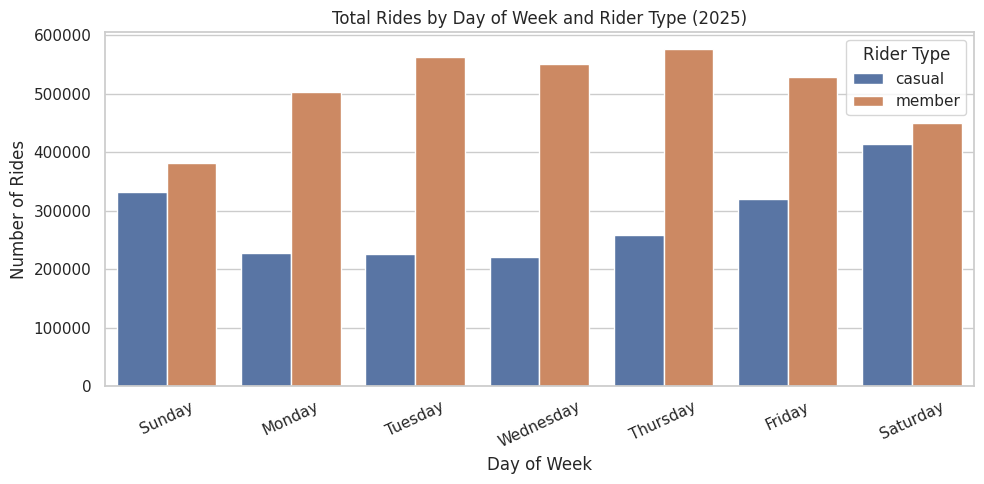

In [18]:
# Step 3: Plot total number of rides by day of week and rider type
plt.figure(figsize=(10, 5))
sns.barplot(
    data=daily_summary,
    x="day_of_week",
    y="number_of_rides",
    hue="member_casual",
)

# Add chart title, axis labels, and legend formatting
plt.title("Total Rides by Day of Week and Rider Type (2025)")
plt.xlabel("Day of Week")
plt.ylabel("Number of Rides")
plt.xticks(rotation=25)
plt.legend(title="Rider Type")
plt.tight_layout()
plt.show()

Member riders reach higher trip counts Tuesday through Friday, whereas casual riders peak on Saturdays and Sundays.

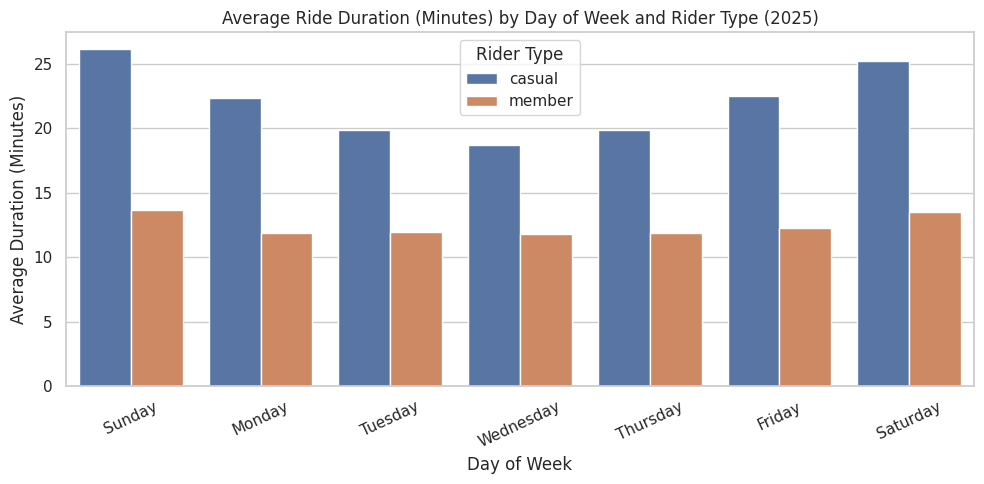

In [19]:
# Step 4: Plot average ride duration (in minutes) by day of week and rider type
plt.figure(figsize=(10, 5))
sns.barplot(
    data=daily_summary,
    x="day_of_week",
    y="avg_duration_min",
    hue="member_casual",
)

# Add chart title, axis labels, and legend formatting
plt.title("Average Ride Duration (Minutes) by Day of Week and Rider Type (2025)")
plt.xlabel("Day of Week")
plt.ylabel("Average Duration (Minutes)")
plt.xticks(rotation=25)
plt.legend(title="Rider Type")
plt.tight_layout()
plt.show()

Casual riders have an overall higher average trip duration than member riders. Both groups peak on weekends (Saturday and Sunday) and record their lowest averages midweek (Wednesday is the lowest for both).

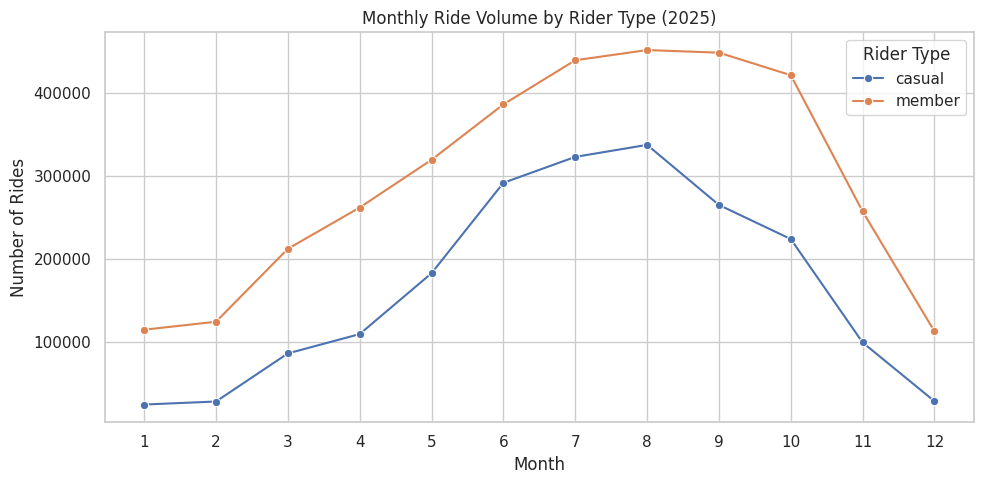

In [20]:
# Step 5: Aggregate and plot monthly ride volume by rider type across 2025
monthly_summary = (
    all_trips_v2.groupby(["month", "member_casual"], as_index=False)
    .agg(number_of_rides=("ride_id", "count"))
    .sort_values("month")
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_summary,
    x="month",
    y="number_of_rides",
    hue="member_casual",
    marker="o",
)

# Add chart title, axis labels, and month ticks (1 to 12)
plt.title("Monthly Ride Volume by Rider Type (2025)")
plt.xlabel("Month")
plt.ylabel("Number of Rides")
plt.xticks(range(1, 13))
plt.legend(title="Rider Type")
plt.tight_layout()
plt.show()

Members account for the highest number of trips throughout the year. Both groups peak during the summer months, and the gap between them widens as overall ridership increases during this period.

### RECOMMENDATIONS

- Introduce flexible, shorter-term memberships: The company can convert casual riders into members by offering flexible subscription tiers with shorter commitment periods, such as weekend-only or seasonal summer passes.

- Adjust pricing structure for extended rides: Since casual riders take longer trips on average, the company should consider offering preferential or capped rates for long-duration rides to incentivise annual membership sign-ups.

- Launch targeted seasonal and weekend campaigns: Marketing campaigns should be initiated to highlight the cost savings and benefits of an annual membership specifically during the summer months, on weekends, and for long-duration rides.